In [1]:
import pandas as pd

df = pd.read_csv("goalies.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (355, 36)

Column names:
['playerId', 'season', 'name', 'team', 'position', 'situation', 'games_played', 'icetime', 'xGoals', 'goals', 'unblocked_shot_attempts', 'xRebounds', 'rebounds', 'xFreeze', 'freeze', 'xOnGoal', 'ongoal', 'xPlayStopped', 'playStopped', 'xPlayContinuedInZone', 'playContinuedInZone', 'xPlayContinuedOutsideZone', 'playContinuedOutsideZone', 'flurryAdjustedxGoals', 'lowDangerShots', 'mediumDangerShots', 'highDangerShots', 'lowDangerxGoals', 'mediumDangerxGoals', 'highDangerxGoals', 'lowDangerGoals', 'mediumDangerGoals', 'highDangerGoals', 'blocked_shot_attempts', 'penalityMinutes', 'penalties']


,playerId,season,name,team,position,situation,games_played,icetime,xGoals,goals,...,highDangerShots,lowDangerxGoals,mediumDangerxGoals,highDangerxGoals,lowDangerGoals,mediumDangerGoals,highDangerGoals,blocked_shot_attempts,penalityMinutes,penalties
0,8478048,2026,Igor Shesterkin,NYR,G,other,5,725.0,0.72,0.0,...,0.0,0.08,0.64,0.00,0.0,0.0,0.0,9.0,0.0,0.0
1,8478048,2026,Igor Shesterkin,NYR,G,all,5,16061.0,12.95,8.0,...,6.0,3.69,7.84,1.42,3.0,5.0,0.0,89.0,0.0,0.0
2,8478048,2026,Igor Shesterkin,NYR,G,5on5,5,12875.0,9.89,6.0,...,6.0,3.20,5.27,1.42,3.0,3.0,0.0,69.0,0.0,0.0
3,8478048,2026,Igor Shesterkin,NYR,G,4on5,5,1500.0,2.34,2.0,...,0.0,0.41,1.93,0.00,0.0,2.0,0.0,10.0,0.0,0.0
4,8478048,2026,Igor Shesterkin,NYR,G,5on4,5,961.0,0.00,0.0,...,0.0,0.00,0.00,0.00,0.0,0.0,0.0,1.0,0.0,0.0


In [2]:
print("Missing values in each column:")
display(df.isna().sum().sort_values(ascending=False).head(15))

print("\nData types:")
display(df.dtypes)

for col in df.columns:
    if any(word in col.lower() for word in
           ["season", "situation", "player", "goalie", "team"]):
        print(f"\n{col}:")
        print(df[col].dropna().unique()[:20])

Missing values in each column:


,0
playerId,0
season,0
name,0
team,0
position,0
situation,0
games_played,0
icetime,0
xGoals,0
goals,0



Data types:


,0
playerId,int64
season,int64
name,object
team,object
position,object
situation,object
games_played,int64
icetime,float64
xGoals,float64
goals,float64



playerId:
[8478048 8478872 8479979 8477968 8476999 8478009 8475311 8480280 8476945
 8477424 8479973 8480947 8481519 8476883 8475809 8476412 8477484 8476434
 8478406 8479193]

season:
[2026]

team:
['NYR' 'UTA' 'DAL' 'SJS' 'OTT' 'NYI' 'LAK' 'BOS' 'NJD' 'NSH' 'WPG' 'VAN'
 'CHI' 'TBL' 'COL' 'STL' 'DET' 'MTL' 'SEA' 'MIN']

situation:
['other' 'all' '5on5' '4on5' '5on4']


In [3]:
# Make column names easier to work with
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print("Available columns:")
for col in df.columns:
    print(col)

Available columns:
playerid
season
name
team
position
situation
games_played
icetime
xgoals
goals
unblocked_shot_attempts
xrebounds
rebounds
xfreeze
freeze
xongoal
ongoal
xplaystopped
playstopped
xplaycontinuedinzone
playcontinuedinzone
xplaycontinuedoutsidezone
playcontinuedoutsidezone
flurryadjustedxgoals
lowdangershots
mediumdangershots
highdangershots
lowdangerxgoals
mediumdangerxgoals
highdangerxgoals
lowdangergoals
mediumdangergoals
highdangergoals
blocked_shot_attempts
penalityminutes
penalties


In [4]:

# STEP A: Inspect the goalie dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Reuse df if it already exists; otherwise load the CSV
if "df" not in globals():
    df = pd.read_csv("goalies.csv")

# Standardise column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print("Dataset size:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head())


Dataset size: (355, 36)

Available columns:
['playerid', 'season', 'name', 'team', 'position', 'situation', 'games_played', 'icetime', 'xgoals', 'goals', 'unblocked_shot_attempts', 'xrebounds', 'rebounds', 'xfreeze', 'freeze', 'xongoal', 'ongoal', 'xplaystopped', 'playstopped', 'xplaycontinuedinzone', 'playcontinuedinzone', 'xplaycontinuedoutsidezone', 'playcontinuedoutsidezone', 'flurryadjustedxgoals', 'lowdangershots', 'mediumdangershots', 'highdangershots', 'lowdangerxgoals', 'mediumdangerxgoals', 'highdangerxgoals', 'lowdangergoals', 'mediumdangergoals', 'highdangergoals', 'blocked_shot_attempts', 'penalityminutes', 'penalties']


,playerid,season,name,team,position,situation,games_played,icetime,xgoals,goals,...,highdangershots,lowdangerxgoals,mediumdangerxgoals,highdangerxgoals,lowdangergoals,mediumdangergoals,highdangergoals,blocked_shot_attempts,penalityminutes,penalties
0,8478048,2026,Igor Shesterkin,NYR,G,other,5,725.0,0.72,0.0,...,0.0,0.08,0.64,0.00,0.0,0.0,0.0,9.0,0.0,0.0
1,8478048,2026,Igor Shesterkin,NYR,G,all,5,16061.0,12.95,8.0,...,6.0,3.69,7.84,1.42,3.0,5.0,0.0,89.0,0.0,0.0
2,8478048,2026,Igor Shesterkin,NYR,G,5on5,5,12875.0,9.89,6.0,...,6.0,3.20,5.27,1.42,3.0,3.0,0.0,69.0,0.0,0.0
3,8478048,2026,Igor Shesterkin,NYR,G,4on5,5,1500.0,2.34,2.0,...,0.0,0.41,1.93,0.00,0.0,2.0,0.0,10.0,0.0,0.0
4,8478048,2026,Igor Shesterkin,NYR,G,5on4,5,961.0,0.00,0.0,...,0.0,0.00,0.00,0.00,0.0,0.0,0.0,1.0,0.0,0.0


In [5]:

import shutil
from google.colab import files

shutil.make_archive("goalie_charts", "zip", "goalie_charts")
files.download("goalie_charts.zip")


FileNotFoundError: [Errno 2] No such file or directory: 'goalie_charts'

In [6]:

import os

print("Current folder:", os.getcwd())
print("Files and folders available:")
print(os.listdir())

print("\nDoes goalie_charts exist?",
      os.path.exists("goalie_charts"))


Current folder: /content
Files and folders available:
['.config', 'goalies.csv', 'sample_data']

Does goalie_charts exist? False


In [8]:

import os
import matplotlib.pyplot as plt

os.makedirs("goalie_charts", exist_ok=True)

# Check whether any charts were actually created
print("Chart folder created.")
print("Files inside:", os.listdir("goalie_charts"))


Chart folder created.
Files inside: []


In [9]:

import pandas as pd
import os

# Find the uploaded CSV file
print("Files available:", os.listdir())

# Load the goalie dataset
if "df" not in globals():
    df = pd.read_csv("goalies.csv")

# Display the exact column names
print("\nCOLUMN NAMES:")
for i, col in enumerate(df.columns):
    print(i, repr(col))

print("\nFIRST FIVE ROWS:")
display(df.head())

print("\nDATASET SIZE:", df.shape)


Files available: ['.config', 'goalie_charts', 'goalies.csv', 'sample_data']

COLUMN NAMES:
0 'playerid'
1 'season'
2 'name'
3 'team'
4 'position'
5 'situation'
6 'games_played'
7 'icetime'
8 'xgoals'
9 'goals'
10 'unblocked_shot_attempts'
11 'xrebounds'
12 'rebounds'
13 'xfreeze'
14 'freeze'
15 'xongoal'
16 'ongoal'
17 'xplaystopped'
18 'playstopped'
19 'xplaycontinuedinzone'
20 'playcontinuedinzone'
21 'xplaycontinuedoutsidezone'
22 'playcontinuedoutsidezone'
23 'flurryadjustedxgoals'
24 'lowdangershots'
25 'mediumdangershots'
26 'highdangershots'
27 'lowdangerxgoals'
28 'mediumdangerxgoals'
29 'highdangerxgoals'
30 'lowdangergoals'
31 'mediumdangergoals'
32 'highdangergoals'
33 'blocked_shot_attempts'
34 'penalityminutes'
35 'penalties'

FIRST FIVE ROWS:


,playerid,season,name,team,position,situation,games_played,icetime,xgoals,goals,...,highdangershots,lowdangerxgoals,mediumdangerxgoals,highdangerxgoals,lowdangergoals,mediumdangergoals,highdangergoals,blocked_shot_attempts,penalityminutes,penalties
0,8478048,2026,Igor Shesterkin,NYR,G,other,5,725.0,0.72,0.0,...,0.0,0.08,0.64,0.00,0.0,0.0,0.0,9.0,0.0,0.0
1,8478048,2026,Igor Shesterkin,NYR,G,all,5,16061.0,12.95,8.0,...,6.0,3.69,7.84,1.42,3.0,5.0,0.0,89.0,0.0,0.0
2,8478048,2026,Igor Shesterkin,NYR,G,5on5,5,12875.0,9.89,6.0,...,6.0,3.20,5.27,1.42,3.0,3.0,0.0,69.0,0.0,0.0
3,8478048,2026,Igor Shesterkin,NYR,G,4on5,5,1500.0,2.34,2.0,...,0.0,0.41,1.93,0.00,0.0,2.0,0.0,10.0,0.0,0.0
4,8478048,2026,Igor Shesterkin,NYR,G,5on4,5,961.0,0.00,0.0,...,0.0,0.00,0.00,0.00,0.0,0.0,0.0,1.0,0.0,0.0



DATASET SIZE: (355, 36)


In [10]:

# STEP 1: Prepare goalie data for analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Keep all-situations records only
goalies = df[df["situation"] == "all"].copy()

# Keep actual goalies
goalies = goalies[goalies["position"] == "G"].copy()

# Remove rows without a goalie name
goalies = goalies.dropna(subset=["name"])

print("Number of goalie records:", len(goalies))
print("Season:", goalies["season"].unique())
print("\nGoalies included:")
display(goalies[["name", "team", "games_played", "goals", "xgoals"]].head(10))


Number of goalie records: 71
Season: [2026]

Goalies included:


,name,team,games_played,goals,xgoals
1,Igor Shesterkin,NYR,5,8.0,12.95
6,Karel Vejmelka,UTA,11,32.0,27.23
11,Jake Oettinger,DAL,9,13.0,22.42
16,Alex Nedeljkovic,SJS,5,15.0,19.53
21,Linus Ullmark,OTT,8,10.0,18.27
26,Ilya Sorokin,NYI,8,18.0,23.71
31,Darcy Kuemper,LAK,7,22.0,20.62
36,Jeremy Swayman,BOS,10,22.0,30.17
41,Connor Hellebuyck,NJD,1,1.0,1.71
46,Juuse Saros,NSH,9,26.0,29.90


In [11]:

# STEP 2: Find available performance measures

print("Available columns:")
print(goalies.columns.tolist())

# Calculate goals saved above expected if the data supports it
if "xgoals" in goalies.columns and "goals" in goalies.columns:
    goalies["goals_saved_above_expected"] = (
        goalies["xgoals"] - goalies["goals"]
    )

print("\nGoalie performance data:")
display(goalies[["name", "team", "games_played",
                 "goals", "xgoals",
                 "goals_saved_above_expected"]].head(15))


Available columns:
['playerid', 'season', 'name', 'team', 'position', 'situation', 'games_played', 'icetime', 'xgoals', 'goals', 'unblocked_shot_attempts', 'xrebounds', 'rebounds', 'xfreeze', 'freeze', 'xongoal', 'ongoal', 'xplaystopped', 'playstopped', 'xplaycontinuedinzone', 'playcontinuedinzone', 'xplaycontinuedoutsidezone', 'playcontinuedoutsidezone', 'flurryadjustedxgoals', 'lowdangershots', 'mediumdangershots', 'highdangershots', 'lowdangerxgoals', 'mediumdangerxgoals', 'highdangerxgoals', 'lowdangergoals', 'mediumdangergoals', 'highdangergoals', 'blocked_shot_attempts', 'penalityminutes', 'penalties']

Goalie performance data:


,name,team,games_played,goals,xgoals,goals_saved_above_expected
1,Igor Shesterkin,NYR,5,8.0,12.95,4.95
6,Karel Vejmelka,UTA,11,32.0,27.23,-4.77
11,Jake Oettinger,DAL,9,13.0,22.42,9.42
16,Alex Nedeljkovic,SJS,5,15.0,19.53,4.53
21,Linus Ullmark,OTT,8,10.0,18.27,8.27
26,Ilya Sorokin,NYI,8,18.0,23.71,5.71
31,Darcy Kuemper,LAK,7,22.0,20.62,-1.38
36,Jeremy Swayman,BOS,10,22.0,30.17,8.17
41,Connor Hellebuyck,NJD,1,1.0,1.71,0.71
46,Juuse Saros,NSH,9,26.0,29.90,3.90


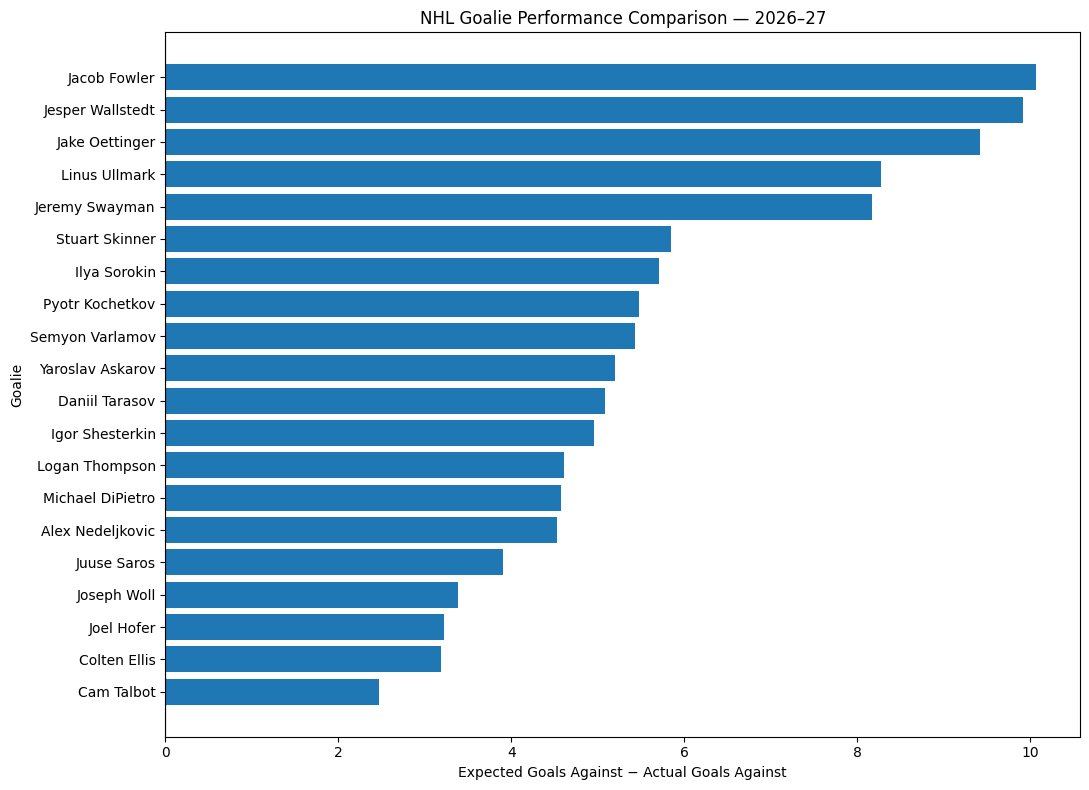

In [12]:

# STEP 3: First visualisation

chart_data = goalies[
    goalies["games_played"] >= 2
].copy()

chart_data = chart_data.dropna(
    subset=["name", "goals_saved_above_expected"]
)

chart_data = chart_data.sort_values(
    "goals_saved_above_expected"
).tail(20)

plt.figure(figsize=(11, 8))
plt.barh(
    chart_data["name"],
    chart_data["goals_saved_above_expected"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Expected Goals Against − Actual Goals Against")
plt.ylabel("Goalie")
plt.title("NHL Goalie Performance Comparison — 2026–27")
plt.tight_layout()

os.makedirs("goalie_charts", exist_ok=True)
plt.savefig(
    "goalie_charts/01_goalie_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


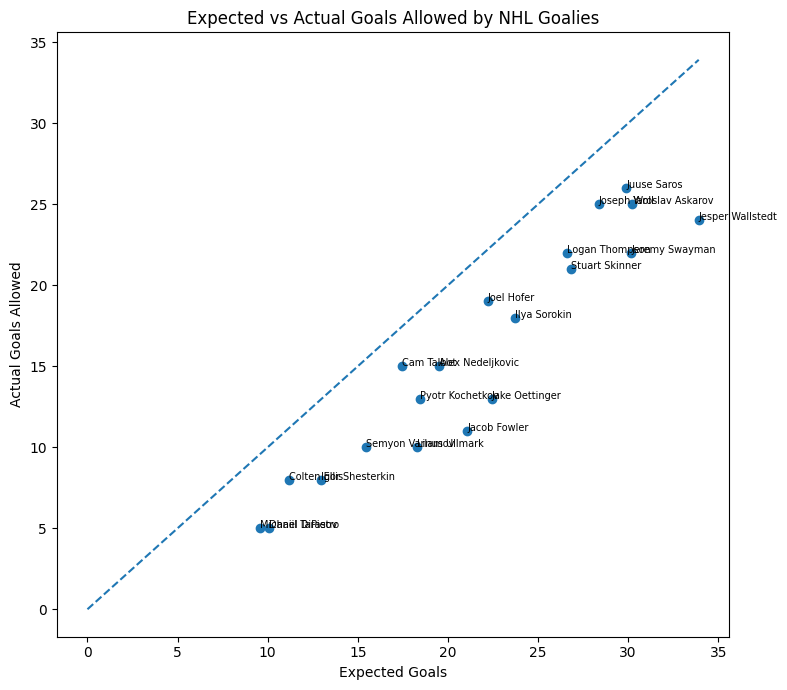

In [13]:

# STEP 4: Expected goals versus goals allowed

plt.figure(figsize=(8, 7))

plt.scatter(
    chart_data["xgoals"],
    chart_data["goals"]
)

for _, row in chart_data.iterrows():
    plt.annotate(
        row["name"],
        (row["xgoals"], row["goals"]),
        fontsize=7
    )

max_value = max(
    chart_data["xgoals"].max(),
    chart_data["goals"].max()
)

plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Expected Goals")
plt.ylabel("Actual Goals Allowed")
plt.title("Expected vs Actual Goals Allowed by NHL Goalies")
plt.tight_layout()

plt.savefig(
    "goalie_charts/02_expected_vs_actual.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [14]:

import shutil
from google.colab import files

shutil.make_archive(
    "goalie_charts",
    "zip",
    "goalie_charts"
)

files.download("goalie_charts.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

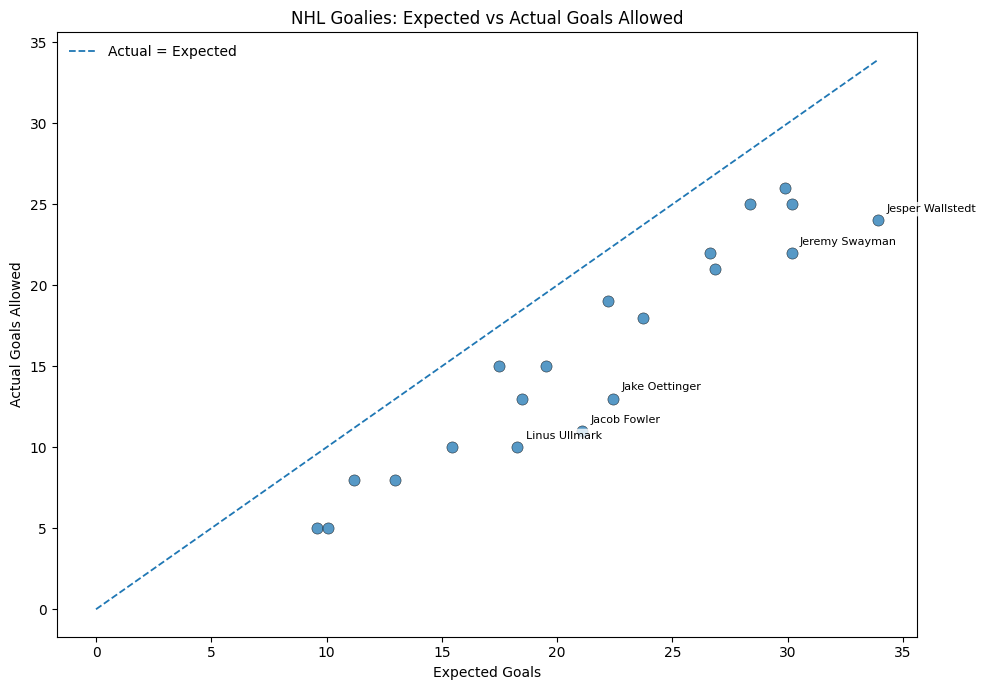

In [15]:

# REVISED CHART 2: Cleaner expected vs actual comparison

import matplotlib.pyplot as plt
import numpy as np
import os

# Use the existing chart_data from your previous analysis
plot_data = chart_data.dropna(
    subset=["xgoals", "goals", "name"]
).copy()

fig, ax = plt.subplots(figsize=(10, 7))

# Plot all goalies without overlapping name labels
ax.scatter(
    plot_data["xgoals"],
    plot_data["goals"],
    s=65,
    alpha=0.75,
    edgecolors="black",
    linewidths=0.4
)

# Reference line: actual goals equal expected goals
max_value = max(
    plot_data["xgoals"].max(),
    plot_data["goals"].max()
)
ax.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    linewidth=1.3,
    label="Actual = Expected"
)

# Label only the five goalies furthest from the reference line
plot_data["difference"] = plot_data["goals"] - plot_data["xgoals"]
label_data = plot_data.loc[
    plot_data["difference"].abs().nlargest(5).index
]

for _, row in label_data.iterrows():
    ax.annotate(
        str(row["name"]),
        (row["xgoals"], row["goals"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8,
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            alpha=0.8,
            edgecolor="none"
        )
    )

ax.set_xlabel("Expected Goals")
ax.set_ylabel("Actual Goals Allowed")
ax.set_title("NHL Goalies: Expected vs Actual Goals Allowed")
ax.legend(frameon=False)
ax.grid(False)
fig.tight_layout()

os.makedirs("goalie_charts", exist_ok=True)
fig.savefig(
    "goalie_charts/02_expected_vs_actual.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [16]:

chart_data[["name", "xgoals", "goals"]].to_csv(
    "goalie_chart_data.csv", index=False
)

from google.colab import files
files.download("goalie_chart_data.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>